## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Evie McMahan

**Date:** 10/12/2026

## Q1 ##

**1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.**

In [468]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

**2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?**

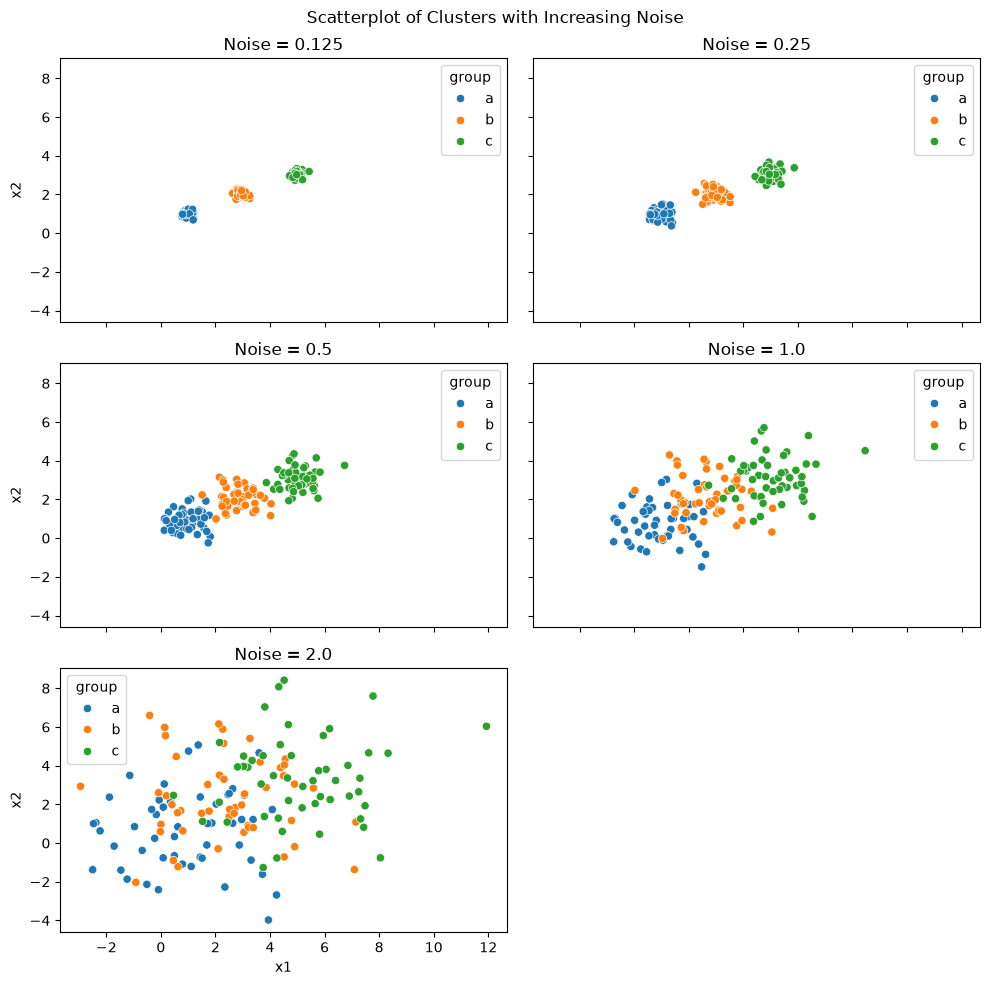

In [469]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

fig, axs = plt.subplots(3,2, figsize=(10,10), sharex=True, sharey=True) # Build subplot structure
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0] # Create list to loop through
positions = [(0,0), (0,1), (1,0), (1,1), (2,0)] # Create list of subplot locations
noise = ['0.125', '0.25', '0.5', '1.0', '2.0'] # Create list of noise level for each dataset

for pos, data, label in zip(positions, datasets, noise): # Loop through positions and dataframe list
    sns.scatterplot(data=data, x='x1', y='x2', hue='group', ax=axs[pos]) # Plot each subplot
    axs[pos].set_title(f"Noise = {label}")

fig.delaxes(axs[2,1]) # Remove empty subplot
plt.suptitle("Scatterplot of Clusters with Increasing Noise")
plt.tight_layout()
plt.show()


As the noise around the center clusters increases from 0.125 to 2.0, the clusters become less visually distinct and overlap with each other. At 0.125, the clusters show 3 tight groups, while at 2.0 the groups overlap heavily.

**3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)**

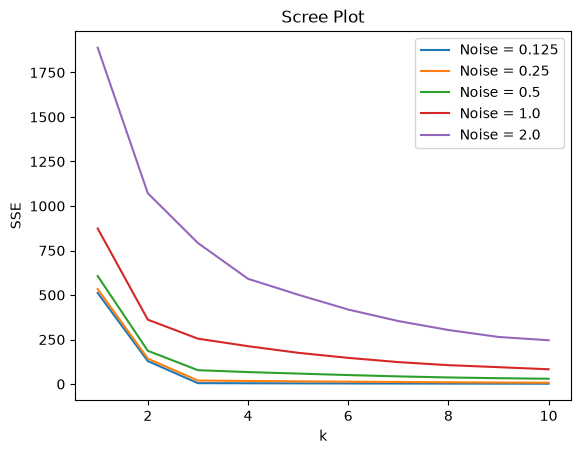

In [470]:
ks = np.arange(1,11) # The range of k's that I will test via my scree plot

features = ['x1', 'x2']

for pos, df, label in zip(positions, datasets, noise): # Loop through positions and dataframe list
    X = df.loc[:, features] # Dataframe of features
    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ 
        for k in ks
    ]
    sns.lineplot(x=ks, y=SSE, label=f"Noise = {label}") # Plot scree

plt.title("Scree Plot")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

I put all the scree curves on a single canvas to be able to easily compare them to each other. As noise increases, it becomes harder to definitively select a k because the "elbows" become less sharp. For example, at a noise of 2.0, SSE continues to decrease substantially throughout the plot and there are no clear "elbows" where a reduction is SSE drops off. At a noise of 0.125, the SSE appears to be very stable and not decrease after its elbow at k = 3. Additionally, the higher the noise, the larger the SSEs for all k values. This makes sense based on the scatterplots in part 1, since the clusters overlap more and more as noise increases. 

**4. Explain the intuition of the elbow, using this numerical simulation as an example.**

The elbow helps us choose the best k to use for our data because it shows the point at which adding another cluster reduces SSE by much less than before. We want to balance having a low SSE (which is a measure of error) and having so many clusters that we split groups that would have been coherent. Using this simulation, at a noise of 0.125, there is still a substantial decrease in error from moving from 2 to 3 centroids. However, at 3 centroids, there is a clear change in the slope of the scree curve, and after k = 3, the line is nearly flat, meaning that there are almost no further reductions in error to be made by increasing k. On the opposite end of the spectrum, at a noise of 2.0, there is barely a change in slope when moving from 3 to 4 centroids, and the SSE keeps decreasing even as k approaches 10, although at a slower rate. This intuitively makes sense because the points are so intertwined and do not form distinct clusters when noise is 2.0, so it is hard to determine the correct number of clusters to use, wheras the points form 3 distinct clusters when the noise is 0.125.

## Q2 ##

**1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?**

In [471]:
df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
print(df.shape)
df.head()

(5882, 7)


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,0,1988,Afghanistan,NaN,NaN,NaN,NaN
1,1,1989,Afghanistan,NaN,NaN,NaN,NaN
2,2,1990,Afghanistan,NaN,NaN,NaN,NaN
3,3,1991,Afghanistan,NaN,NaN,NaN,NaN
4,4,1992,Afghanistan,NaN,NaN,NaN,NaN


In [472]:
filtered_df = df[df['Year'] == 2020] # Select only year 2020
filtered_df = filtered_df.dropna() # Drop all rows with missing values

print(filtered_df.shape)
filtered_df.head()
print(f"Number of countries: {filtered_df['Country'].nunique()}")

filtered_df.describe()

(148, 7)
Number of countries: 148


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


In [473]:
print(filtered_df.dtypes)

col = 'Spending (2020 USD)'

max_spending_id = filtered_df[col].idxmax() # Take id of the highest spending columns
second_max_spending_id = filtered_df[col].drop(max_spending_id).idxmax() # Second highest spending

max_spending = filtered_df.loc[max_spending_id] # Grab the full max spending row
second_max_spending = filtered_df.loc[second_max_spending_id] # Grab the full second max spending row

print(f"\nHighest spending country: {max_spending['Country']} ({max_spending[col]:,.2f} million)")
print(f"Second highest spending country: {second_max_spending['Country']} ({second_max_spending[col]:,.2f} million)")

index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object

Highest spending country: United States of America (778,397.20 million)
Second highest spending country: China (257,973.43 million)


After dropping rows with missing values and selecting only the year 2020, I also ended up with 148 countries. This confirms there are no duplicate countries. I also checked the data types of each variable to ensure they were correct. Index and Year are integers, Country is a string, and the rest of the variables are floats, which is what I anticipated. The other area I wanted to check before concluding that no other cleaning is required is the extreme max values in Spending, as well as Spending Per Capita. Spending had a max value of $778,397 million, while it's mean was $13,154 million. This extreme outlier is also far outside of the IQR of $205 million to $5,283 million. However, I found that this was the United States, and as a result I didn't remove it from the dataset. It is meaningful data and not an input error, for example. The next second highest spending country was China at $257,973 million, which is far behind the US. After doing some inspection, I determined that no additional cleaning was needed. All of these spending numbers are in millions, which I found out after googling the US' actual millitary 2020 expenditures.

**2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?**


In [474]:
features = ['Spending (2020 USD)', 'Spending per Capita']
unscaled = filtered_df.loc[:, features] # Select the features
mins = unscaled.min() # Determine minimums for each feature
ranges = unscaled.max() - mins # Determine ranges for each feature
X = (unscaled - mins) / ranges # Scale the feature variables

X.agg(['min', 'max']) # Check the scaling

,Spending (2020 USD),Spending per Capita
min,0.0,0.0
max,1.0,1.0


I first min-max normalized the two feature variables.

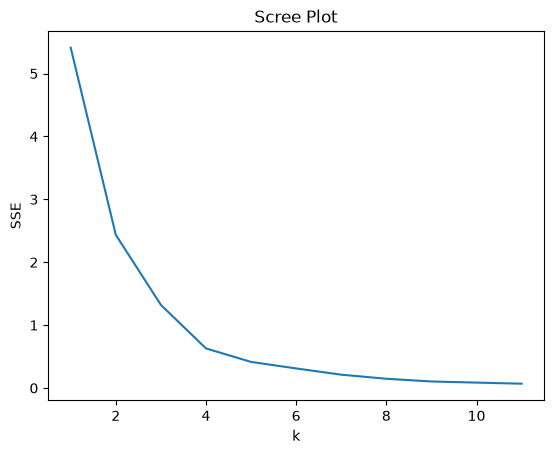

In [475]:
ks = np.arange(1,12) # The range of k's that I will test via my scree plot
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

I built my scree plot by looping through k's of 1 through 11, and determing the SSE for each k. After plotting, I determined that the optimal number of clusters is 4 since there is a sharp point that shows a meaningful decrease in SSE before, while the reduction is smaller after. 

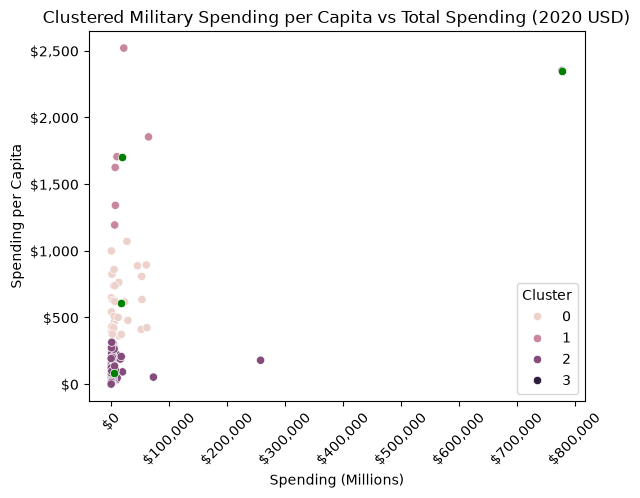

In [476]:
import matplotlib.ticker as mticker

k = 4
model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
filtered_df['cluster'] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()
ax = sns.scatterplot(data=filtered_df, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster')
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color='green', ax=ax) # Plot the centers a different color

ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}')) # Format y axis
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}')) # Format x axis
plt.xticks(rotation=45)

plt.title("Clustered Military Spending per Capita vs Total Spending (2020 USD)")
plt.xlabel('Spending (Millions)')
plt.ylabel('Spending per Capita')
plt.legend(title="Cluster")
plt.show()

In [477]:
filtered_df.groupby('cluster')[features].describe().sort_values(('Spending (2020 USD)', 'mean'))

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
2                     111.0    4859.185065  25405.739131       8.622460   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
2           130.010211     382.464677    2297.032353  257973.429834   
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
2                     111.0    80.061470   83.501824     0.580129   
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
3                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
2          14.880549    47.056944   125.387558   314.201312  
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
3        2351.631858  2351.631858  2351.631858  2351.631858

The United States is clearly the outlier in this dataset. It is the only point in its cluster because of how high its military spending and spending per capita are compared to the other 147 countries, which I discussed in greater detail in response to Q2, part 1. Compared to the United States, the rest of the countries have relatively similar total spending, with the mean of the remaining clusters increasing from $4,859 million to $19,443 million as spending per capita increases. In general, across clusters, higher total spending goes along with higher spending per capita; however, the increase in total spending across these clusters is very small compared to the United States’ total spending of $778,397 million. The clusters do clearly separate cohorts of countries based on spending per capita, as mean spending per capita increases steadily from $80 to $1,707 excluding the US, and $2,352 including the US.

**3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?**

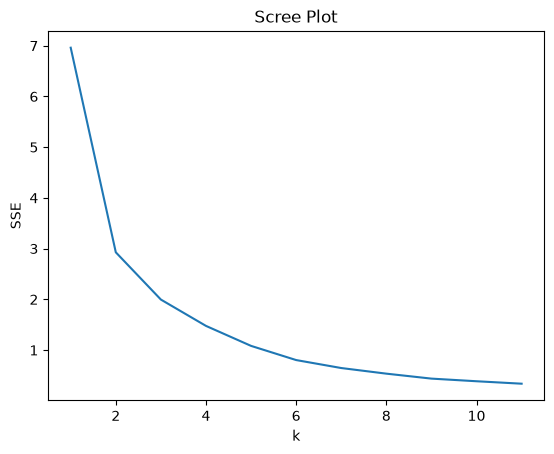

In [478]:
new_features = ['Percent of Government Spending', 'Percent of GDP']
new_unscaled = filtered_df.loc[:, new_features] # Select the features
new_mins = new_unscaled.min() # Determine minimums for each feature
new_ranges = new_unscaled.max() - new_mins # Determine ranges for each feature
new_X = (new_unscaled - new_mins) / new_ranges # Scale the feature variables

new_X.agg(['min', 'max']) # Check the scaling

ks = np.arange(1,12) # The range of k's that I will test via my scree plot
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(new_X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()


I will choose a k of 4 for these feature variables because it appears to be the sharpest elbow, and the decrease in SSE is smaller after this point.

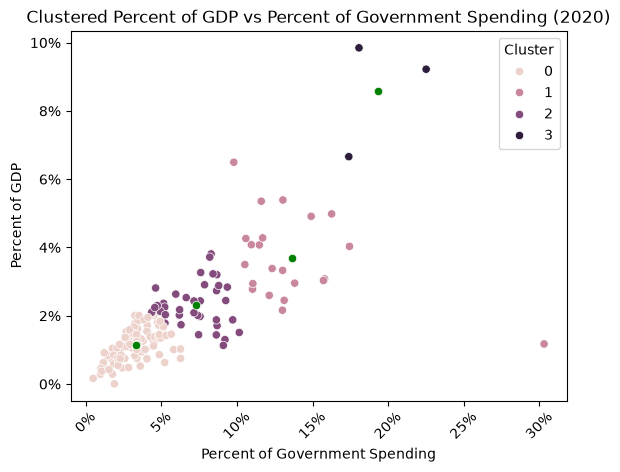

In [479]:
k = 4
model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(new_X)
filtered_df['cluster'] = model.labels_
centers = model.cluster_centers_ * new_ranges.to_numpy() + new_mins.to_numpy()
ax = sns.scatterplot(data=filtered_df, x='Percent of Government Spending', y='Percent of GDP', hue='cluster')
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color='green', ax=ax) # Plot the centers a different color

ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.0%}')) # Format y axis
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0%}')) # Format x axis
plt.xticks(rotation=45)

plt.title("Clustered Percent of GDP vs Percent of Government Spending (2020)")
plt.legend(title="Cluster")
plt.show()

In [480]:
filtered_df.groupby('cluster')[new_features].describe().sort_values(('Percent of Government Spending', 'mean'))

Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 86.0  0.033019  0.013198  0.004896   
2                                 37.0  0.072669  0.016870  0.043592   
1                                 22.0  0.136158  0.042661  0.097882   
3                                  3.0  0.193209  0.027779  0.173924   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.022977  0.032821  0.042267  0.062685           86.0  0.011394   
2        0.059520  0.075583  0.086497  0.101501           37.0  0.023079   
1        0.111561  0.126638  0.146304  0.303027           22.0  0.036932   
3        0.177289  0.180654  0.202852  0.225050            3.0  0.085760   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.004816  0.000054  0.007542  0.011341  0.014507  0.020535  
2        0.006411  0.011317  0.018801  0.022408  0.027340  0.038118  
1        0.012381  0.011742  0.029458  0.034419  0.042766  0.064961  
3        0.016886  0.066600  0.079405  0.092211  0.095341  0.098470

The first thing that is different about these results versus part 2 is that the US no longer has its own cluster. In part 2, the fact that the US was an extreme outlier in total spending meant that the cluster division was mainly driven by spending per capita. However, in this plot there is not one extreme outlier, and as a result the clusters separated by both increases in % of goverment spending and % of GDP. There is also a stronger positive linear relationship between % of government spending and % of GDP than there was between the two axes in part 2. The counts of countries in each cluster are a little more even in this graph, with the most populated cluster composed of 86 countries versus 111 in part 2.  

**4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?**

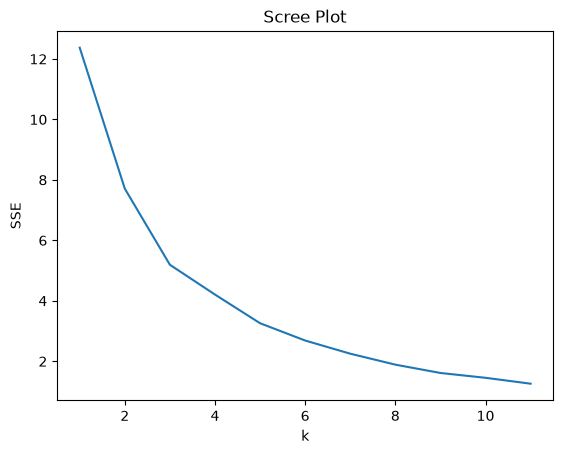

In [481]:
final_features = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
final_unscaled = filtered_df.loc[:, final_features] # Select the features
final_mins = final_unscaled.min() # Determine minimums for each feature
final_ranges = final_unscaled.max() - final_mins # Determine ranges for each feature
final_X = (final_unscaled - final_mins) / final_ranges # Scale the feature variables

final_X.agg(['min', 'max']) # Check the scaling

ks = np.arange(1,12) # The range of k's that I will test via my scree plot
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(final_X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()


Although this scree plot is less helpful in helping me determine a k value, I will use k = 5 because it is the highest k value with a clear elbow. 

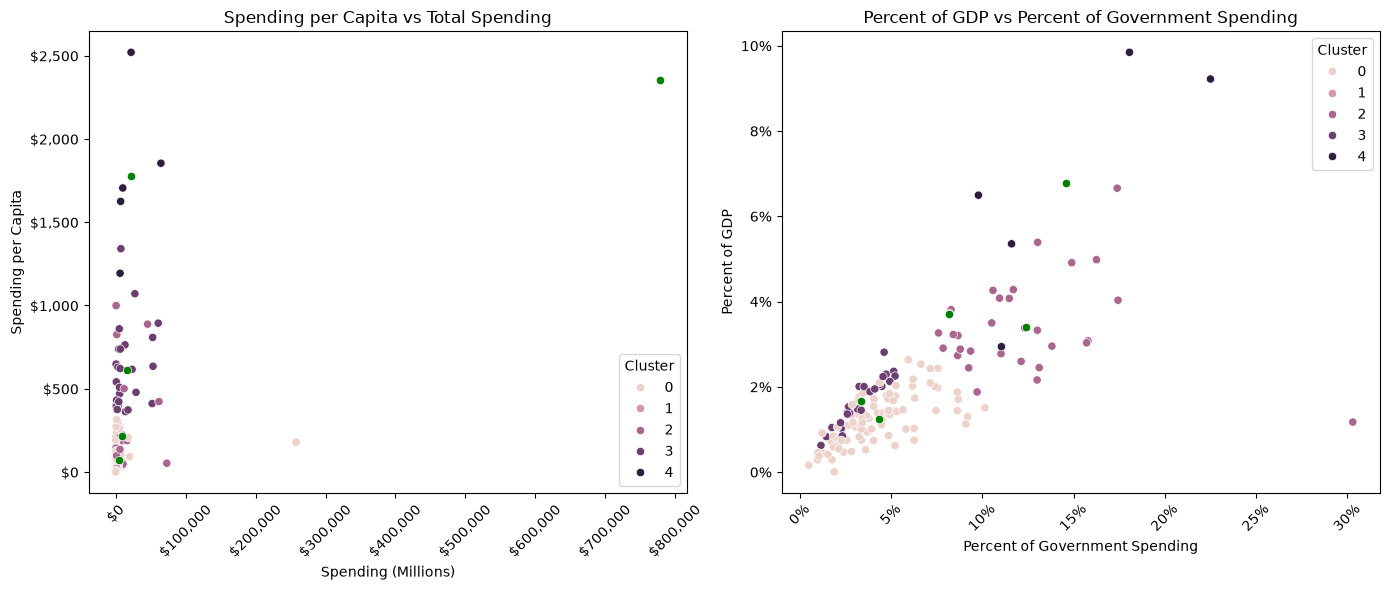

In [482]:
k = 5
model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(final_X)
filtered_df['cluster'] = model.labels_
centers = model.cluster_centers_ * final_ranges.to_numpy() + final_mins.to_numpy()

fig, axs = plt.subplots(1,2, figsize=(14,6)) # Build subplot

# Plot 1: Spending variables (columns 0 and 1)
sns.scatterplot(data=filtered_df, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster', ax=axs[0])
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color='green', ax=axs[0]) # Plot the centers a different color
axs[0].yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}')) # Format y axis
axs[0].xaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}')) # Format x axis
axs[0].tick_params(axis='x', rotation=45)
axs[0].set_title("Spending per Capita vs Total Spending")
axs[0].set_xlabel('Spending (Millions)')
axs[0].legend(title="Cluster")

# Right: percent variables
sns.scatterplot(data=filtered_df, x='Percent of Government Spending', y='Percent of GDP', hue='cluster', ax=axs[1])
sns.scatterplot(x=centers[:, 2], y=centers[:, 3], color='green', ax=axs[1]) # Plot the centers a different color
axs[1].yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.0%}')) # Format y axis
axs[1].xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.0%}')) # Format x axis
axs[1].tick_params(axis='x', rotation=45)
axs[1].set_title("Percent of GDP vs Percent of Government Spending")
axs[1].legend(title="Cluster")

plt.tight_layout()
plt.show()

In [483]:
filtered_df.groupby('cluster')[final_features].describe().sort_values(('Spending (2020 USD)', 'mean'))

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      86.0    4513.543790  27841.230783       8.622460   
2                      30.0    9073.543709  18135.032885     163.926877   
3                      26.0   15330.618681  18923.469359     405.790494   
4                       5.0   21878.058451  24674.937388    6095.708713   
1                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0            81.022976     288.061512    1138.618231  257973.429834   
2           522.737081    1663.090134    8646.648849   72937.064048   
3          3176.345598    5857.060906   21818.934764   60675.039625   
4          6941.042345    9978.571429   21816.569767   64558.400000   
1        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      86.0    70.290644  ...                       0.053006   
2                      30.0   215.920971  ...                       0.136403   
3                      26.0   612.677541  ...                       0.044645   
4                       5.0  1779.854530  ...                       0.180654   
1                       1.0  2351.631858  ...                       0.081976   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.101501           86.0  0.012481  0.005799  0.000054  0.007811   
2        0.303027           30.0  0.034105  0.011116  0.011742  0.027933   
3        0.052209           26.0  0.016585  0.005525  0.006273  0.013689   
4        0.225050            5.0  0.067725  0.028372  0.029429  0.053553   
1        0.081976            1.0  0.037179       NaN  0.037179  0.037179   

                                       
              50%       75%       max  
cluster                                
0        0.012532  0.016783  0.026340  
2        0.032148  0.040637  0.066600  
3        0.015324  0.020431  0.028132  
4        0.064961  0.092211  0.098470  
1        0.037179  0.037179  0.037179  

[5 rows x 32 columns]

When clustering on all four feature variables, my results show clusters that looked much less distinct. The scree plot showed a less definitive k, and as a result the choice of how many clusters to split the data by was more subjective. I chose to plot both scatterplots from part 2 and 3 to compare the clusters. With 5 clusters, the US has its own group again, but the remaining clusters overlap in both scatterplots. This is because the groups are defined by four variables at once, making them harder to interpret visually on a 2-D scatterplot.

**5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?**

Yes, and clustering by different feature variables helped show different patterns. For example, the main takeaway from clustering on total spending and spending per capita was that the US was an extreme outlier. This led the clusters to be grouped primarily on spending per capita. As a result, large standard deviations in each clusters' total spending demonstrated that countries with similar spending per capita could have very different overall levels of military spending. Additionally, when clustering on percent of GDP and percent of government spending, I found a pattern by comparing the number of countries in each cluster. The largest clusters concentrated at the lower end of % of GDP and % of government spending, meaning these countries put less of their dollars towards military spending. At the high end of the range, the cluster with the highest mean % of GDP and government spending consisted of only three countries. 

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [484]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]